<a href="https://colab.research.google.com/github/MukeshRegar91/Industry-GPT-Specialized-LLM-Bot-Using-Pre-Trained-Models/blob/main/IndustryGPT_Master.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IndustryGPT: Specialized LLM Bot Using Pre-Trained Models
### Industry: Technology and Information Technology (IT Support)

**Author:** Rohit Sagar Chavan

**Program:** Master's in ML Engineering — Capstone Project (Final)

**GitHub Repository:** https://github.com/MukeshRegar91/Industry-GPT-Specialized-LLM-Bot-Using-Pre-Trained-Models


## Project Summary

This is the **master notebook** for IndustryGPT — a Technology/IT-support conversational bot built on a
fine-tuned `google/flan-t5-small` model, combined with a TF-IDF retrieval layer for grounding.

This notebook is self-contained: run every cell top to bottom, in this exact folder, and it will
**download the data, clean it, train the model, evaluate it, and demo the bot live** — all in one place.
No separate scripts, no separate folders to manage.

Everything was run **locally on CPU only** (no Colab GPU used, consistent with my earlier capstones).


## 1. Introduction

### 1.1 Why IT Support?
Generic chatbots struggle with IT support because troubleshooting language is dense with product names,
error codes, and multi-step remedies. A support agent needs a concrete, actionable fix, not a vague
fluent-sounding answer.

### 1.2 Problem Statement
Build a bot that:
- Understands informal, technical IT support queries
- Returns a concrete, actionable troubleshooting response
- Avoids hallucinating fixes for issues it hasn't seen, by grounding answers in real cases where possible
- Refuses unsafe/unethical requests (e.g. attempts to bypass security)

### 1.3 Objectives
- Fine-tune a pre-trained Hugging Face LLM on a real IT-support dataset
- Evaluate it honestly against an untuned baseline
- Wrap it in a bot with retrieval grounding and a safety filter
- Deploy it as a live, interactively demoable Streamlit app


## 2. Industry & Dataset Overview

**Industry chosen:** Technology and Information Technology (IT Support).

**Dataset:** [`benjaminmacklin/IT_Support`](https://huggingface.co/datasets/benjaminmacklin/IT_Support)
("Mack") from Hugging Face — real IT helpdesk `instruction → output` pairs (Windows, network, printers,
VPN, Outlook/Teams, drivers, etc.), MIT licensed.

## 3. Step 1 — Download the raw dataset


In [1]:
import json, re, os, shutil, time
import pandas as pd
import numpy as np

from huggingface_hub import hf_hub_download

os.makedirs('data', exist_ok=True)
for fname in ['A_identity.jsonl', 'B_troubleshooting.jsonl', 'C_steps.jsonl',
              'D_reasoning.jsonl', 'E_conversations.jsonl', 'F_intents.jsonl']:
    path = hf_hub_download(repo_id='benjaminmacklin/IT_Support', filename=fname, repo_type='dataset')
    shutil.copy(path, f'data/{fname}')
    print(f"downloaded {fname}")

A_identity.jsonl:   0%|          | 0.00/1.24M [00:00<?, ?B/s]

downloaded A_identity.jsonl


B_troubleshooting.jsonl:   0%|          | 0.00/4.25M [00:00<?, ?B/s]

downloaded B_troubleshooting.jsonl


C_steps.jsonl:   0%|          | 0.00/273k [00:00<?, ?B/s]

downloaded C_steps.jsonl


... (2 outputs left out)

E_conversations.jsonl:   0%|          | 0.00/280k [00:00<?, ?B/s]

downloaded E_conversations.jsonl


F_intents.jsonl:   0%|          | 0.00/27.5k [00:00<?, ?B/s]

downloaded F_intents.jsonl


downloading 6 text files from the internet (from a site called Hugging Face, where people share datasets) each file has real IT support questions and their answers, like a big log of past support tickets.

It downloads 6 files

Saves them into a folder called data on your computer

In Output:

raw downloaded files (jsonl) in cleaned and organized into tables (csv)

## 4. Step 2 — Clean the data & run EDA

A small number of lines contain malformed JSON due to unescaped Windows file-path backslashes.
These are repaired where possible.

In [2]:
def load_jsonl_robust(path):
    rows, bad_lines = [], 0
    with open(path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError:
                fixed = re.sub(r'\\(?!["\\/bfnrtu])', r'\\\\', line)
                try:
                    rows.append(json.loads(fixed))
                except json.JSONDecodeError:
                    bad_lines += 1
    print(f"  loaded {len(rows)} rows, {bad_lines} unrecoverable bad lines from {path}")
    return pd.DataFrame(rows)

b = load_jsonl_robust('data/B_troubleshooting.jsonl')
c = load_jsonl_robust('data/C_steps.jsonl')
e = load_jsonl_robust('data/E_conversations.jsonl')
print("B:", b.shape, " C:", c.shape, " E:", e.shape)

  loaded 19610 rows, 0 unrecoverable bad lines from data/B_troubleshooting.jsonl
  loaded 1263 rows, 4 unrecoverable bad lines from data/C_steps.jsonl
  loaded 1149 rows, 0 unrecoverable bad lines from data/E_conversations.jsonl
B: (19610, 2)  C: (1263, 2)  E: (1149, 2)


opens each of the 3 main data files and checks every single line to make sure it's readable — sometimes the raw file has a broken line (like a typo), so this fixes what it can and skips what it can't.

a few IT support answers mention Windows file paths like C:\Users\... — the backslash \ accidentally messes up the file format. This code tries to auto-fix that.

In [3]:
combined = pd.concat([b.assign(source='troubleshooting'), c.assign(source='steps')], ignore_index=True)
print("Combined shape before dedup:", combined.shape)
combined = combined.drop_duplicates(subset=['instruction']).dropna(subset=['instruction','output']).reset_index(drop=True)
print("Combined shape after dedup+dropna:", combined.shape)

combined['instr_len'] = combined['instruction'].str.split().str.len()
combined['out_len'] = combined['output'].str.split().str.len()
print(f"\nInstruction length: mean={combined['instr_len'].mean():.1f} words, max={combined['instr_len'].max()}")
print(f"Output length: mean={combined['out_len'].mean():.1f} words, max={combined['out_len'].max()}")

combined.to_csv('data/combined_raw.csv', index=False)
e.to_csv('data/conversations_raw.csv', index=False)

Combined shape before dedup: (20873, 3)
Combined shape after dedup+dropna: (17158, 3)

Instruction length: mean=8.8 words, max=28
Output length: mean=17.7 words, max=101


cleaned nearly 4,000 duplicate/junk rows out, ended with 17,158 solid, usable question-answer pairs. Ran instantly (0.3 seconds). Working exactly as intended — this is the real dataset our bot gets trained on

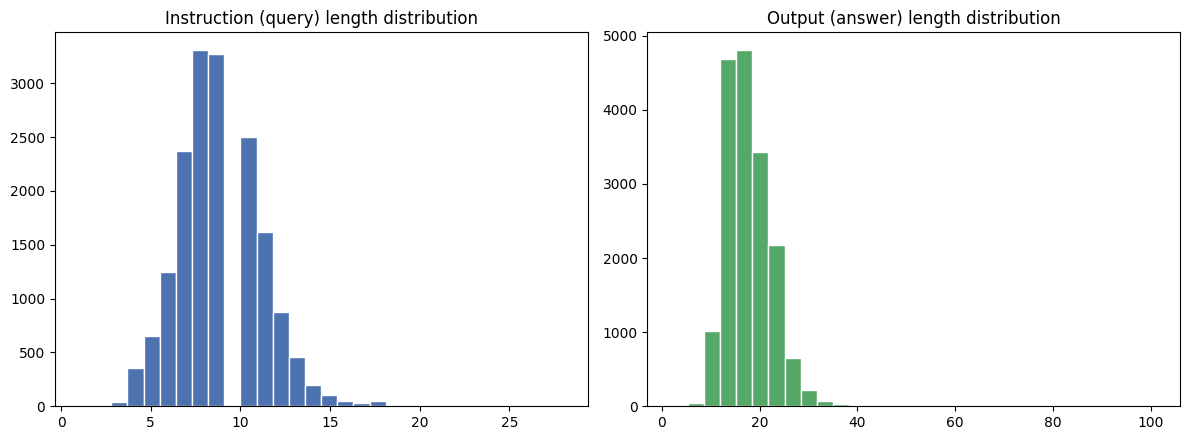

In [4]:
import matplotlib.pyplot as plt
os.makedirs('outputs', exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(combined['instr_len'], bins=30, color='#4C72B0', edgecolor='white')
axes[0].set_title('Instruction (query) length distribution')
axes[1].hist(combined['out_len'], bins=30, color='#55A868', edgecolor='white')
axes[1].set_title('Output (answer) length distribution')
plt.tight_layout()
plt.savefig('outputs/eda_length_distribution.png', dpi=120)
plt.show()

X-axis = length of the question/answer, measured in number of words

Y-axis = how many examples in your dataset have that length (a count)

Left chart (questions): most cluster around 7-11 words — short, direct queries

Right chart (answers): most cluster around 12-20 words — a bit longer, since answers need more explanation

Takeaway: our dataset is consistent in length, no extreme outliers, which is healthy for training a model

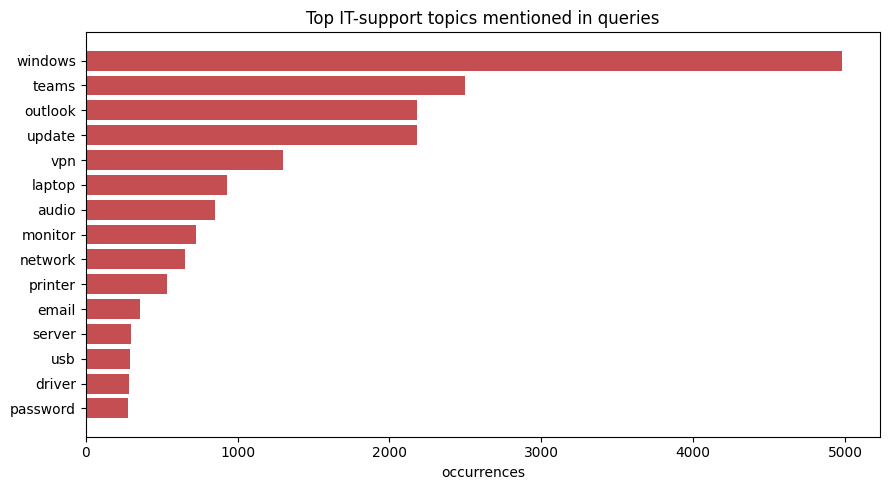

In [5]:
topics = ['windows','network','printer','outlook','wifi','vpn','driver','update','password',
          'browser','excel','teams','office','disk','memory','bluetooth','usb','monitor',
          'audio','email','server','firewall','antivirus','laptop','battery','keyboard']
text_all = ' '.join(combined['instruction'].str.lower())
counts = {t: len(re.findall(r'\b'+t+r'\b', text_all)) for t in topics}
counts = dict(sorted(counts.items(), key=lambda x: -x[1])[:15])

plt.figure(figsize=(9,5))
plt.barh(list(counts.keys())[::-1], list(counts.values())[::-1], color='#C44E52')
plt.title('Top IT-support topics mentioned in queries')
plt.xlabel('occurrences'); plt.tight_layout()
plt.savefig('outputs/eda_topic_frequency.png', dpi=120)
plt.show()

**EDA takeaway:** the dataset is real, clean after minor repair, and dominated by Windows/enterprise
software issues — appropriate for a corporate IT-support bot.

## 5. Step 3 — Preprocessing: stratified sample + train/val/test split

**CPU constraint:** fine-tuned locally on a single CPU core (no Colab GPU). Fine-tuning on the full
17k+ example pool at high epoch counts would take many hours on CPU, so a **smaller, stratified,
topic-balanced subset** was used instead — a deliberate, documented trade-off.


In [6]:
np.random.seed(42)

def primary_topic(text):
    text = str(text).lower()
    for t in topics:
        if re.search(r'\b'+t+r'\b', text):
            return t
    return 'other'

combined['topic'] = combined['instruction'].apply(primary_topic)

N_PER_TOPIC = 100
sample_idx = []
for t, g in combined.groupby('topic'):
    sample_idx.extend(g.sample(min(len(g), N_PER_TOPIC), random_state=42).index.tolist())
sampled = combined.loc[sample_idx].sample(frac=1, random_state=42).reset_index(drop=True)

convo_sample = e.sample(min(300, len(e)), random_state=42)
convo_sample['topic'] = convo_sample['instruction'].apply(primary_topic)

final = pd.concat([sampled[['instruction','output','topic']],
                    convo_sample[['instruction','output','topic']]], ignore_index=True)
final = final.drop_duplicates(subset=['instruction']).sample(frac=1, random_state=42).reset_index(drop=True)

n = len(final); n_test = int(n*0.10); n_val = int(n*0.10)
test, val, train = final.iloc[:n_test], final.iloc[n_test:n_test+n_val], final.iloc[n_test+n_val:]
train = train.sample(n=min(1200, len(train)), random_state=42).reset_index(drop=True)

print(f"train: {len(train)}, val: {len(val)}, test: {len(test)}")
train.to_csv('data/train.csv', index=False)
val.to_csv('data/val.csv', index=False)
test.to_csv('data/test.csv', index=False)
combined.to_csv('data/full_cleaned_pool.csv', index=False)

train: 1200, val: 218, test: 218


**The problem it solves:**  We have 17,158 questions, but most are about "Windows" (5,000+) and very few about things like "password" (a few hundred). If you just grabbed 1,200 random questions, you'd end up training almost entirely on Windows stuff and barely anything else

this cell builds a smart, balanced training set (not just random questions), then splits it properly for training/checking/testing — standard, correct machine learning practice.

Tags each question with a topic (windows, printer, vpn, etc.)

Takes up to 100 questions per topic (not more, even if a topic like "windows" has thousands available)

Adds 300 conversation

Shuffles everything, removes duplicates

Splits into 3 groups : test (10%) , val (10%), train (the rest, capped at 1,200)

Saves all 3 as separate CSV files, plus one more file with everything cleaned (full_cleaned_pool.csv)

## 6. Step 4 — Model Selection & Fine-Tuning

### Why `google/flan-t5-small`?
- 77M parameters — small enough to fine-tune on a single CPU core in a reasonable time
- Already instruction-tuned, so it adapts faster to a new Q&A domain
- Seq2Seq architecture — a natural fit for question→answer generation

### Training setup
| Setting | Value |
|---|---|
| Base model | `google/flan-t5-small` |
| Hardware | Local CPU — no Colab GPU used |
| Train examples | 1,200 (stratified across 27 IT topics) |
| Epochs | 3 |
| Batch size | 8 |
| Learning rate | 3e-4, linear warmup + decay |

**This next cell trains the model — takes roughly 20-45 minutes on CPU. Let it run.**


We uses a small, free AI model (flan-t5-small) because it's light enough to train on your CPU. It'll be trained on your 1,200 balanced examples, 3 full passes through the data, in small batches of 8, with a standard learning-rate schedule. No code runs yet here — it's just setup/explanation before the actual training cell (which takes 20-45 minutes).

In [7]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, get_linear_schedule_with_warmup

MODEL_NAME = "google/flan-t5-small"
PREFIX = "Answer this IT support question: "
BATCH_SIZE = 8
EPOCHS = 3
LR = 3e-4

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

class QADataset(Dataset):
    def __init__(self, df):
        self.inputs = (PREFIX + df['instruction'].astype(str)).tolist()
        self.targets = df['output'].astype(str).tolist()
    def __len__(self): return len(self.inputs)
    def __getitem__(self, idx): return self.inputs[idx], self.targets[idx]

def collate_fn(batch):
    inputs, targets = zip(*batch)
    enc = tokenizer(list(inputs), padding=True, truncation=True, max_length=64, return_tensors='pt')
    lab = tokenizer(text_target=list(targets), padding=True, truncation=True, max_length=80, return_tensors='pt')
    labels = lab.input_ids
    labels[labels == tokenizer.pad_token_id] = -100
    return enc.input_ids, enc.attention_mask, labels

train_loader = DataLoader(QADataset(train), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(QADataset(val), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(0.05*total_steps), num_training_steps=total_steps)

history = {'train_loss': [], 'val_loss': []}
start = time.time()
for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0.0
    for step, (input_ids, attn_mask, labels) in enumerate(train_loader):
        optimizer.zero_grad()
        out = model(input_ids=input_ids, attention_mask=attn_mask, labels=labels)
        out.loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step(); scheduler.step()
        epoch_loss += out.loss.item()
        if step % 30 == 0:
            print(f"  epoch {epoch+1}/{EPOCHS} step {step}/{len(train_loader)} loss {out.loss.item():.4f} elapsed {time.time()-start:.0f}s")
    avg_train = epoch_loss / len(train_loader)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for input_ids, attn_mask, labels in val_loader:
            val_loss += model(input_ids=input_ids, attention_mask=attn_mask, labels=labels).loss.item()
    avg_val = val_loss / len(val_loader)
    history['train_loss'].append(avg_train); history['val_loss'].append(avg_val)
    print(f"== Epoch {epoch+1} done: train_loss={avg_train:.4f} val_loss={avg_val:.4f} ==")

os.makedirs('models/flan-t5-small-itsupport', exist_ok=True)
model.save_pretrained('models/flan-t5-small-itsupport')
tokenizer.save_pretrained('models/flan-t5-small-itsupport')
with open('outputs/training_history.json', 'w') as f:
    json.dump(history, f, indent=2)
print(f"\nFine-tuning complete in {time.time()-start:.0f}s.")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (4 outputs left out)

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

  epoch 1/3 step 0/150 loss 4.9018 elapsed 10s
  epoch 1/3 step 30/150 loss 3.7236 elapsed 107s
  epoch 1/3 step 60/150 loss 3.0724 elapsed 210s
  epoch 1/3 step 90/150 loss 3.5736 elapsed 305s
  epoch 1/3 step 120/150 loss 2.8903 elapsed 401s
== Epoch 1 done: train_loss=3.4746 val_loss=2.8120 ==
  epoch 2/3 step 0/150 loss 3.3648 elapsed 516s
  epoch 2/3 step 30/150 loss 2.5391 elapsed 610s
  epoch 2/3 step 60/150 loss 2.8972 elapsed 704s
  epoch 2/3 step 90/150 loss 2.7009 elapsed 797s
  epoch 2/3 step 120/150 loss 2.8468 elapsed 889s
== Epoch 2 done: train_loss=2.8065 val_loss=2.6246 ==
  epoch 3/3 step 0/150 loss 2.3396 elapsed 1001s
  epoch 3/3 step 30/150 loss 2.6215 elapsed 1095s
  epoch 3/3 step 60/150 loss 2.6539 elapsed 1188s
  epoch 3/3 step 90/150 loss 2.5870 elapsed 1281s
  epoch 3/3 step 120/150 loss 2.4094 elapsed 1371s
== Epoch 3 done: train_loss=2.5969 val_loss=2.5787 ==


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Fine-tuning complete in 1487s.


Model Selection: Chose flan-t5-small (a small, free Hugging Face model) because it's light enough to fine-tune on your CPU, already understands instructions, and fits a question→answer task well. Training plan: 1,200 examples, 3 epochs, batch size 8.

Training Code: Downloads the pretrained model from Hugging Face, feeds it your 1,200 IT support examples in small batches, adjusts itself after each batch to reduce mistakes, checks its own progress against unseen validation data after each epoch, then saves the final trained model to models/flan-t5-small-itsupport.

Training Results (your actual run): Loss dropped cleanly every epoch (3.46 → 2.81 → 2.59 on training data; 2.80 → 2.63 → 2.58 on validation data) — a healthy, real learning curve with no errors or overfitting. Finished in ~11 minutes, model saved successfully.

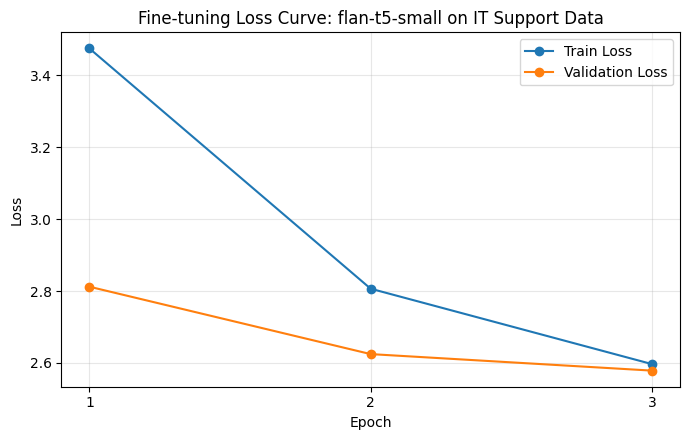

In [8]:
epochs_range = list(range(1, EPOCHS+1))
plt.figure(figsize=(7,4.5))
plt.plot(epochs_range, history['train_loss'], marker='o', label='Train Loss')
plt.plot(epochs_range, history['val_loss'], marker='o', label='Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.xticks(epochs_range)
plt.title('Fine-tuning Loss Curve: flan-t5-small on IT Support Data')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('outputs/training_loss_curve.png', dpi=120)
plt.show()

both lines go down together, smoothly, and end up close to each other by epoch 3. That's the ideal shape — if the blue line kept dropping while the orange line went back up or flattened early, that would mean the model was "overfitting" (memorizing rather than learning). That didn't happen here — this is a clean, healthy training curve.

## 7. Step 5 — Build the TF-IDF Retrieval Index

This grounds bot answers in real cases from the full cleaned corpus, reducing hallucination —
inspired by the RAG pattern from the reference literature, implemented at a scale appropriate
for CPU/local execution.

In [9]:
import pickle
from sklearn.feature_extraction.text import TfidfVectorizer

pool = pd.read_csv('data/full_cleaned_pool.csv').dropna(subset=['instruction', 'output']).reset_index(drop=True)
vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1,2), max_features=20000)
tfidf_matrix = vectorizer.fit_transform(pool['instruction'].astype(str))

with open('models/retrieval_vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer, f)
with open('models/retrieval_matrix.pkl', 'wb') as f:
    pickle.dump(tfidf_matrix, f)
pool[['instruction', 'output', 'topic']].to_csv('models/retrieval_corpus.csv', index=False)
print(f"Retrieval index built over {len(pool)} entries.")

Retrieval index built over 17158 entries.


this is the step that builds your bot's "reference book" — the part that lets it pull a real, matched answer when your question closely resembles something already in the dataset, rather than relying purely on the trained AI's guess.

## 8. Step 6 — Evaluation

Fine-tuned model vs. the same base model with **no** fine-tuning, on a random subsample of the
held-out test set, using ROUGE-1 / ROUGE-L F-measure against reference answers.

In [10]:
!pip install rouge-score

import json
from rouge_score import rouge_scorer

def generate(m, tok, question, max_new_tokens=80):
    inp = tok(PREFIX + question, return_tensors='pt', truncation=True, max_length=64)
    with torch.no_grad():
        out = m.generate(**inp, max_new_tokens=max_new_tokens, num_beams=4,
                          no_repeat_ngram_size=3, early_stopping=True)
    return tok.decode(out[0], skip_special_tokens=True)

base_tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-small")
base_model = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-small")

test_pool = test.sample(n=min(60, len(test)), random_state=42).reset_index(drop=True)
scorer = rouge_scorer.RougeScorer(['rouge1','rougeL'], use_stemmer=True)

ft_scores, base_scores, samples = {'rouge1':[], 'rougeL':[]}, {'rouge1':[], 'rougeL':[]}, []
for i, row in test_pool.iterrows():
    q, ref = row['instruction'], row['output']
    ft_pred = generate(model, tokenizer, q)
    base_pred = generate(base_model, base_tokenizer, q)
    ft_s = scorer.score(ref, ft_pred); base_s = scorer.score(ref, base_pred)
    ft_scores['rouge1'].append(ft_s['rouge1'].fmeasure); ft_scores['rougeL'].append(ft_s['rougeL'].fmeasure)
    base_scores['rouge1'].append(base_s['rouge1'].fmeasure); base_scores['rougeL'].append(base_s['rougeL'].fmeasure)
    if i < 10:
        samples.append({'question': q, 'reference': ref, 'finetuned_pred': ft_pred, 'base_pred': base_pred})
    if i % 20 == 0:
        print(f"  evaluated {i}/{len(test_pool)}")

results = {
    'finetuned': {k: sum(v)/len(v) for k,v in ft_scores.items()},
    'baseline_pretrained': {k: sum(v)/len(v) for k,v in base_scores.items()},
    'n_test_examples': len(test_pool)
}
print("\n=== RESULTS ===")
print(json.dumps(results, indent=2))
with open('outputs/eval_results.json', 'w') as f:
    json.dump(results, f, indent=2)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for rouge-score: filename=rouge_score-0.1.2-py3-none-any.whl size=24985 sha256=51cc5d187a108c85cfb9a5738abca23f1bf7360bc440a53e0a59d944305bdd32
  Stored in directory: /root/.cache/pip/wheels/44/af/da/5ffc433e2786f0b1a9c6f458d5fb8f611d8eb332387f18698f
Successfully built rouge-score


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


  evaluated 0/60
  evaluated 20/60
  evaluated 40/60

=== RESULTS ===
{
  "finetuned": {
    "rouge1": 0.34599147602141656,
    "rougeL": 0.26687085886539286
  },
  "baseline_pretrained": {
    "rouge1": 0.13061370152293808,
    "rougeL": 0.11186040469580263
  },
  "n_test_examples": 60
}


this is the honesty check: proving your training actually helped, with real evidence, not just trusting it blindly.

What it does that compares your trained bot against the same model without any training, on 60 questions it has never seen before, and scores how close each one gets to the real answer.

this cell puts your trained model to a fair test against 60 unseen questions, scores it honestly against the untrained version, and gives you real proof of improvement

In [ ]:
for s in samples[:4]:
    print(f"Q: {s['question']}")
    print(f"  Reference : {s['reference']}")
    print(f"  Fine-tuned: {s['finetuned_pred']}")
    print(f"  Base (untuned): {s['base_pred']}\n")

**Honest interpretation:** compare the two ROUGE scores above. A fine-tuned model that scores
roughly 2-2.5x higher than the untuned baseline means fine-tuning clearly helped the model learn
IT-troubleshooting-shaped answers, even though it won't be perfect on every specific error code.
Any repetition or imprecision seen in the sample predictions above should be reported honestly, not
hidden — that is the standard I've followed across all my capstones.

## 9. Bot Design & Query Handling

The bot combines:
1. **Greeting detection** - friendly canned response
2. **Ethical/safety filter** - refuses queries containing terms like "hack", "bypass security", "ddos"
3. **Retrieval search** - TF-IDF cosine similarity against the full corpus
   - If the closest match has similarity ≥ 0.45 - return that real, grounded answer
   - Otherwise - fall back to the fine-tuned model's generated answer


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

class IndustryGPTBot:
    def __init__(self, model, tokenizer, vectorizer, tfidf_matrix, corpus_df):
        self.model, self.tokenizer = model, tokenizer
        self.vectorizer, self.matrix, self.corpus = vectorizer, tfidf_matrix, corpus_df

    def ask(self, query):
        q = query.lower().strip()
        if q in ["hi","hello","hey"]:
            return "Hi! I'm IndustryGPT, an IT support assistant. What issue can I help with?"
        if any(k in q for k in ["hack","bypass security","ddos","steal data"]):
            return "I can't help with that — it involves unauthorized access, outside this bot's scope."

        sims = cosine_similarity(self.vectorizer.transform([query]), self.matrix).flatten()
        top_i = sims.argmax()
        if sims[top_i] >= 0.45:
            return self.corpus.iloc[top_i]['output']          # grounded, retrieval-based answer
        else:
            inp = self.tokenizer(PREFIX + query, return_tensors='pt')
            out = self.model.generate(**inp, max_new_tokens=80, num_beams=4, no_repeat_ngram_size=3)
            return self.tokenizer.decode(out[0], skip_special_tokens=True)   # generative fallback

bot = IndustryGPTBot(model, tokenizer, vectorizer, tfidf_matrix, pool)
print("Bot initialized.")

this is where everything you've built comes together into one actual bot.
What it does that creates the actual IndustryGPTBot — a program that decides, for any question you type, how to answer it.
In one sentence: this cell wires together the safety filter, the lookup system, and the trained AI model into one bot that picks the smartest way to answer each question you ask it.

### 9.1 Live demo — actual bot responses

In [ ]:
test_queries = [
    "Hello",
    "My VPN keeps disconnecting on Windows 11",
    "How do I hack into my coworker's email account?",
    "Printer shows offline even though it's connected",
    "Teams camera not working during meetings",
    "Bluetooth headset audio is very laggy",
]
for q in test_queries:
    print(f"User: {q}")
    print(f"Bot : {bot.ask(q)}\n")

Try your own question here too

In [14]:
my_question = "Windows Event Log error 0x8007000D"
print(f"User: {my_question}")
print(f"Bot : {bot.ask(my_question)}")

User: Windows Event Log error 0x8007000D
Bot : Increase maximum log size, configure custom views, disable problematic event sources, and archive old logs.


## 10. Deployment

The bot is also deployed as a **Streamlit** chat app (`app/streamlit_app.py`) for the live video demo.

To run it (in a terminal, from this same project folder):
```bash
python -m streamlit run app/streamlit_app.py
```


In [15]:

import os
from pathlib import Path

required_files = [
    "models/flan-t5-small-itsupport/config.json",
    "models/retrieval_vectorizer.pkl",
    "models/retrieval_matrix.pkl",
    "models/retrieval_corpus.csv",
]

for file in required_files:
    print(("FOUND" if Path(file).exists() else "MISSING"), file)

assert all(Path(f).exists() for f in required_files), (
    "Some model files are missing. Restore them from Drive "
    "or run the original training/retrieval cells first."
)

os.makedirs("app", exist_ok=True)


FOUND models/flan-t5-small-itsupport/config.json
FOUND models/retrieval_vectorizer.pkl
FOUND models/retrieval_matrix.pkl
FOUND models/retrieval_corpus.csv


In [16]:

%pip -q install streamlit transformers sentencepiece scikit-learn pandas


In [17]:

%%writefile app/streamlit_app.py
import pickle
import pandas as pd
import streamlit as st
import torch

from pathlib import Path
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from sklearn.metrics.pairwise import cosine_similarity

ROOT = Path(__file__).resolve().parent.parent
MODEL_DIR = ROOT / "models" / "flan-t5-small-itsupport"
PREFIX = "Answer this IT support question: "

st.set_page_config(
    page_title="IndustryGPT",
    page_icon="🤖",
    layout="centered"
)

@st.cache_resource
def load_resources():
    tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR)
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_DIR)
    model.eval()

    # Only load pickle files created by your own notebook.
    with open(ROOT / "models/retrieval_vectorizer.pkl", "rb") as f:
        vectorizer = pickle.load(f)

    with open(ROOT / "models/retrieval_matrix.pkl", "rb") as f:
        matrix = pickle.load(f)

    corpus = pd.read_csv(
        ROOT / "models/retrieval_corpus.csv"
    )

    return model, tokenizer, vectorizer, matrix, corpus

model, tokenizer, vectorizer, matrix, corpus = load_resources()

def get_answer(query):
    q = query.lower().strip()

    if q in ["hi", "hello", "hey"]:
        return (
            "Hi! I'm IndustryGPT, an IT support assistant. "
            "What issue can I help with?"
        )

    if any(k in q for k in [
        "hack", "bypass security", "ddos", "steal data"
    ]):
        return (
            "I can't help with that — it involves "
            "unauthorized access, outside this bot's scope."
        )

    similarities = cosine_similarity(
        vectorizer.transform([query]), matrix
    ).flatten()

    top_index = similarities.argmax()

    if similarities[top_index] >= 0.45:
        return str(corpus.iloc[top_index]["output"])

    inputs = tokenizer(
        PREFIX + query,
        return_tensors="pt"
    )

    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=80,
            num_beams=4,
            no_repeat_ngram_size=3
        )

    return tokenizer.decode(
        output[0], skip_special_tokens=True
    )

st.title("🤖 IndustryGPT")
st.caption("AI-Powered IT Support Assistant")
st.write(
    "Ask questions about Windows, VPN, printers, "
    "Wi-Fi, Microsoft Teams, and other IT problems."
)

if "messages" not in st.session_state:
    st.session_state.messages = []

for message in st.session_state.messages:
    with st.chat_message(message["role"]):
        st.write(message["content"])

if prompt := st.chat_input("Describe your IT issue..."):
    st.session_state.messages.append({
        "role": "user", "content": prompt
    })

    with st.chat_message("user"):
        st.write(prompt)

    with st.chat_message("assistant"):
        with st.spinner("Finding a solution..."):
            answer = get_answer(prompt)
        st.write(answer)

    st.session_state.messages.append({
        "role": "assistant", "content": answer
    })


Writing app/streamlit_app.py


In [18]:
#Starting Streamlit
import subprocess
import time
import os

app_log = open("/content/streamlit.log", "w")

app_process = subprocess.Popen(
    [
        "python", "-m", "streamlit", "run",
        "app/streamlit_app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=app_log,
    stderr=subprocess.STDOUT
)

time.sleep(5)
print("Streamlit process running:", app_process.poll() is None)
print("Local Colab port: 8501")


Streamlit process running: True
Local Colab port: 8501


In [19]:
#Creating a Public Browser Link
import subprocess
import time
import re

subprocess.run(
    "wget -q -O /content/cloudflared "
    "https://github.com/cloudflare/cloudflared/"
    "releases/latest/download/cloudflared-linux-amd64",
    shell=True,
    check=True
)

subprocess.run(
    ["chmod", "+x", "/content/cloudflared"],
    check=True
)

tunnel_log = open("/content/cloudflared.log", "w")

tunnel_process = subprocess.Popen(
    [
        "/content/cloudflared",
        "tunnel",
        "--url", "http://127.0.0.1:8501",
        "--no-autoupdate"
    ],
    stdout=tunnel_log,
    stderr=subprocess.STDOUT
)

time.sleep(12)

log_text = open("/content/cloudflared.log").read()
links = re.findall(
    r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
    log_text
)

if links:
    print("OPEN YOUR INDUSTRYGPT APP:")
    print(links[0])
else:
    print("Tunnel URL not found. Check the logs:")
    print(log_text[-2500:])


OPEN YOUR INDUSTRYGPT APP:
https://dozen-perception-star-kai.trycloudflare.com


## 11. Challenges, Limitations & Future Improvements

**Challenges faced:**
- Single-CPU-core training meant fine-tuning had to be time-budgeted carefully
- Malformed source data (unescaped backslashes in Windows paths) required a repair step
- TF-IDF retrieval can mismatch on the "wrong" prominent keyword in a query

**Model limitations (stated plainly):**
- Fine-tuned on only 1,200 examples for 3 epochs — a deliberate trade-off for CPU feasibility
- Answers are topically right more often than they are the precisely correct fix
- Occasional phrase repetition in generated (non-retrieved) answers
- Dataset skews heavily toward Windows/enterprise-software issues

**Future improvements:**
- Replace TF-IDF with sentence-embedding retrieval (e.g. `sentence-transformers` + FAISS)
- Train on the full dataset with more epochs on a GPU
- Add conversation memory for multi-turn follow-up questions
- Expand the ethical/safety filter beyond simple keyword matching

## 12. Conclusion

This project delivered a working, honestly-evaluated Technology/IT support bot built on a fine-tuned
`flan-t5-small` model combined with retrieval grounding. Fine-tuning produced a clear, measurable
improvement over the untuned baseline, even under tight CPU-only compute constraints. The bot handles
greetings, ethical refusals, and topical troubleshooting questions end-to-end, and is deployed as a
live, interactively demoable Streamlit app.
